In [2]:
import os, subprocess

try:
    root = subprocess.check_output(
        ["git", "rev-parse", "--show-toplevel"],
        stderr=subprocess.DEVNULL, text=True,
    ).strip()
    os.chdir(root)
except Exception:
    pass  # not in a git repo, leave the CWD alone

In [1]:
import pandas as pd

In [12]:
FILE = "data/raw/esa/matas_data/Merged/master_10m.csv"

In [3]:
df = pd.read_csv("data/raw/esa/matas_data/Merged/master_10m.csv")

In [9]:
df

,lon,lat,x_utm,y_utm,s2_red_reflectance,s2_nir_reflectance,ndvi,fvc,s2_scl_class,worldcover_2021_class,...,tcd_2023_pct,imd_2021_pct,imd_2024_pct,ua_lclu_2021_code,ua_bbh_2021_m,ua_street_tree_2021,lst_downscaled_K,lst_downscaled_C,lst_cell_id,lst_interpolated_K
0,12.565801,55.732706,347155.0,6179015.0,0.0794,0.1568,NaN,NaN,NaN,50,...,NaN,90.0,90.0,11100.0,NaN,0,307.29,34.14,36.0,306.51
1,12.565807,55.732616,347155.0,6179005.0,0.1228,0.2150,NaN,NaN,NaN,50,...,NaN,87.0,87.0,11100.0,NaN,1,307.29,34.14,36.0,306.51
2,12.565966,55.732619,347165.0,6179005.0,0.0732,0.2086,NaN,NaN,NaN,50,...,NaN,80.0,80.0,11100.0,NaN,1,307.29,34.14,36.0,306.51
3,12.566125,55.732622,347175.0,6179005.0,0.0658,0.1998,NaN,NaN,NaN,50,...,NaN,70.0,70.0,12230.0,NaN,1,307.29,34.14,36.0,306.51
4,12.565812,55.732526,347155.0,6178995.0,0.1512,0.1908,NaN,NaN,NaN,50,...,NaN,94.0,94.0,11100.0,NaN,0,307.98,34.83,111.0,306.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1030986,12.509066,55.613010,343115.0,6165825.0,0.0852,0.2442,NaN,NaN,NaN,80,...,0.0,0.0,0.0,23000.0,NaN,0,NaN,NaN,2869.0,NaN
1030987,12.509225,55.613013,343125.0,6165825.0,0.0612,0.2076,NaN,NaN,4.0,10,...,0.0,0.0,0.0,50000.0,NaN,0,NaN,NaN,2869.0,NaN
1030988,12.516051,55.613061,343555.0,6165815.0,0.0680,0.3068,NaN,NaN,NaN,30,...,0.0,0.0,0.0,23000.0,NaN,0,NaN,NaN,2871.0,NaN
1030989,12.516056,55.612972,343555.0,6165805.0,0.0420,0.3144,NaN,NaN,NaN,30,...,0.0,0.0,0.0,23000.0,NaN,0,NaN,NaN,2871.0,NaN


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_corr_heatmap(df):
    corr = df.corr(numeric_only=True)

    plt.figure(figsize=(18, 14))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        annot_kws={"size": 8},
        square=False
    )

    plt.xticks(rotation=45, ha="right", fontsize=10)
    plt.yticks(fontsize=10)
    plt.title("Correlation Heatmap", fontsize=16)

    plt.tight_layout()
    plt.show()

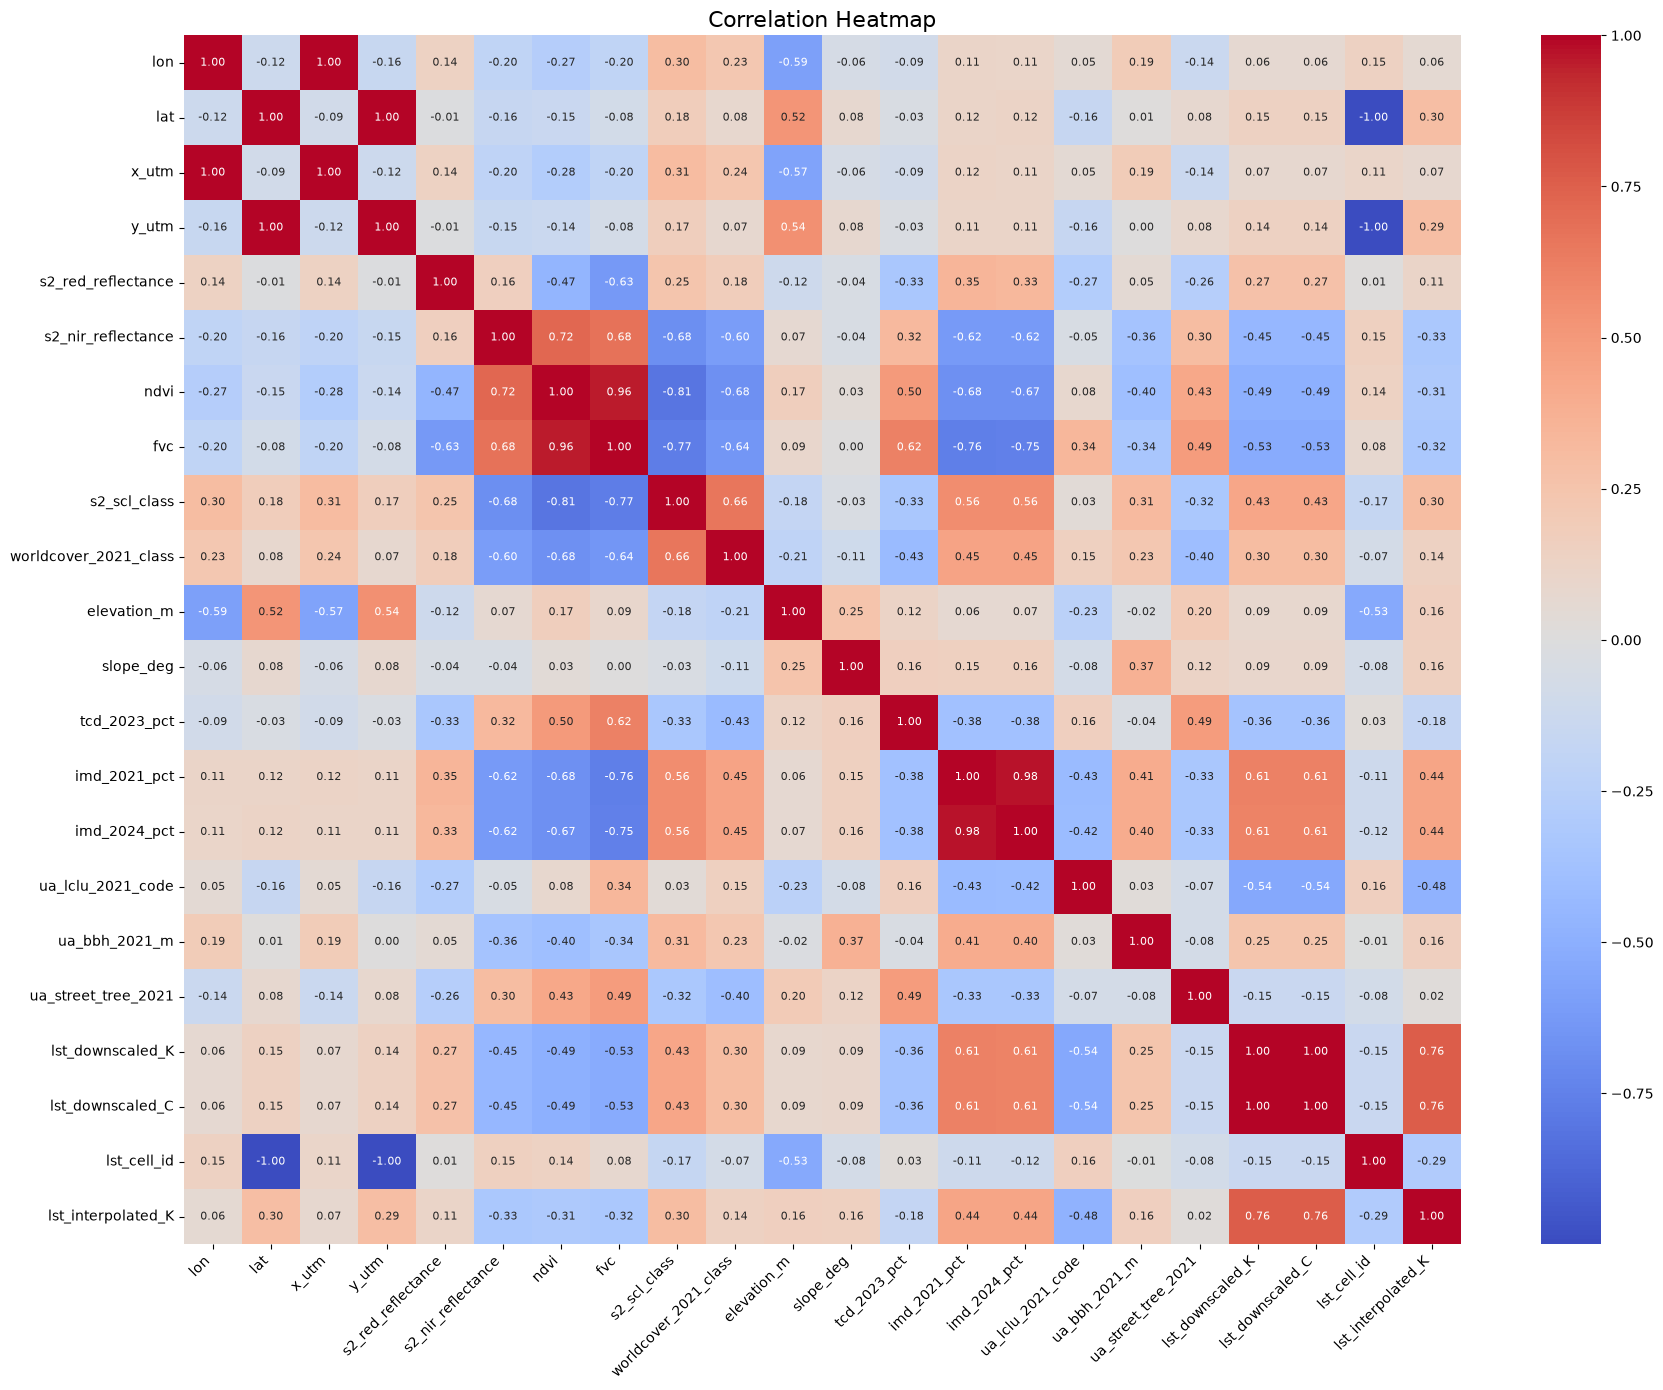

In [8]:
plot_corr_heatmap(df)

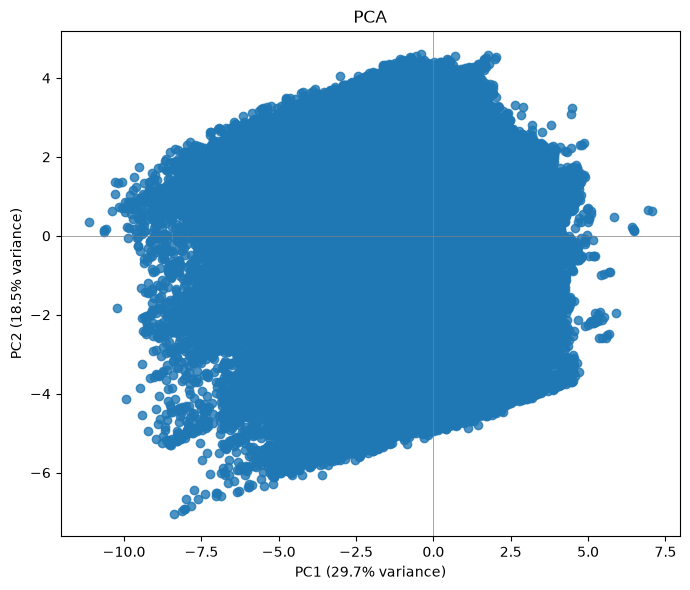

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Load your table
df = pd.read_csv(FILE)

# 2. Pick the numeric columns (and optionally a label column for colors)
label_col = None  # set to None if you have no labels
X = df.select_dtypes(include="number").dropna()
labels = df.loc[X.index, label_col] if label_col else None

# 3. Standardize (important: PCA is sensitive to scale)
X_scaled = StandardScaler().fit_transform(X)

# 4. Run PCA
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)
var = pca.explained_variance_ratio_ * 100

# 5. Plot
fig, ax = plt.subplots(figsize=(7, 6))
if labels is not None:
    for name, grp in pd.DataFrame(pcs, index=X.index).groupby(labels):
        ax.scatter(grp[0], grp[1], label=name, alpha=0.8)
    ax.legend(title=label_col)
else:
    ax.scatter(pcs[:, 0], pcs[:, 1], alpha=0.8)

ax.set_xlabel(f"PC1 ({var[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1f}% variance)")
ax.set_title("PCA")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
plt.tight_layout()
plt.show()

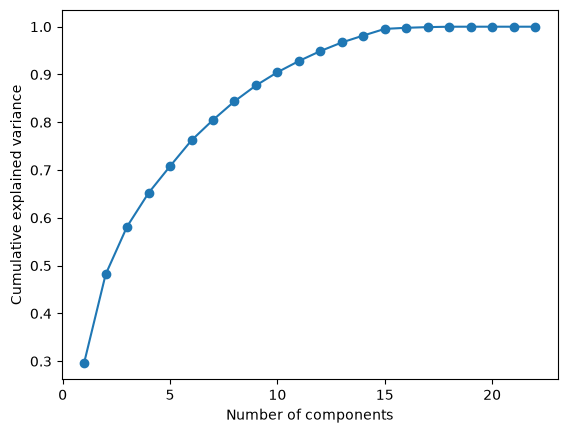

In [16]:
pca_full = PCA().fit(X_scaled)
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         pca_full.explained_variance_ratio_.cumsum(), marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.show()

In [17]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
print(loadings)

                            PC1       PC2
lon                    0.175974 -0.272013
lat                   -0.079186  0.446412
x_utm                  0.175296 -0.259202
y_utm                 -0.084195  0.449840
s2_red_reflectance     0.100935  0.041261
s2_nir_reflectance    -0.270123 -0.083078
ndvi                  -0.337354 -0.113236
fvc                   -0.334189 -0.119022
s2_scl_class           0.297466  0.083864
worldcover_2021_class  0.257686  0.091686
elevation_m           -0.107748  0.391200
slope_deg              0.131225  0.101643
tcd_2023_pct          -0.087738 -0.031091
imd_2021_pct           0.346909  0.116598
imd_2024_pct           0.344301  0.118905
ua_lclu_2021_code      0.050585 -0.022833
ua_bbh_2021_m          0.194530  0.052243
ua_street_tree_2021   -0.131339 -0.069972
lst_downscaled_K       0.220124 -0.036361
lst_downscaled_C       0.220124 -0.036361
lst_cell_id            0.082714 -0.448657
lst_interpolated_K     0.156829 -0.044698


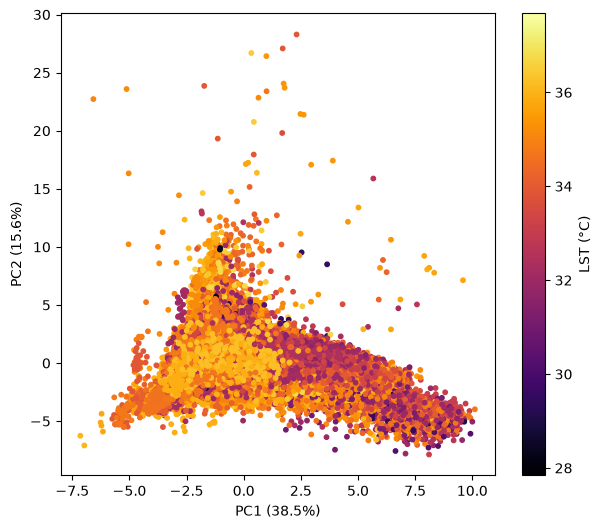

In [18]:
drop = ["lon", "lat", "x_utm", "y_utm",              # coordinates (duplicated)
        "lst_cell_id",                                # ID
        "s2_scl_class", "worldcover_2021_class", "ua_lclu_2021_code",  # categorical
        "lst_downscaled_C", "imd_2024_pct"]           # duplicates

feat = df.drop(columns=drop + ["lst_downscaled_K", "lst_interpolated_K"])
X = feat.select_dtypes("number").dropna()

X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=df.loc[X.index, "lst_downscaled_C"],
                cmap="inflip" if False else "inferno", s=10)
plt.colorbar(sc, label="LST (°C)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.show()

In [21]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
print(loadings)

                          PC1       PC2
s2_red_reflectance  -0.146215  0.646451
s2_nir_reflectance   0.360509  0.442201
ndvi                 0.476049 -0.136354
fvc                  0.474415 -0.157208
elevation_m          0.057696 -0.200934
slope_deg           -0.201987 -0.367082
tcd_2023_pct         0.148041 -0.210212
imd_2021_pct        -0.459828 -0.041613
ua_bbh_2021_m       -0.271351 -0.266799
ua_street_tree_2021  0.214116 -0.225892


In [20]:
print(pca_full.explained_variance_ratio_)
print(pca_full.explained_variance_ratio_.cumsum())

[2.96885164e-01 1.84729348e-01 1.00272185e-01 7.02086003e-02
 5.59442654e-02 5.42149312e-02 4.25845212e-02 3.89806960e-02
 3.31795805e-02 2.76937383e-02 2.34540852e-02 2.08312795e-02
 1.80348448e-02 1.44608879e-02 1.39263445e-02 2.32034619e-03
 1.38680423e-03 8.48602892e-04 4.37676450e-05 6.97398397e-09
 8.79529562e-10 0.00000000e+00]
[0.29688516 0.48161451 0.5818867  0.6520953  0.70803956 0.76225449
 0.80483901 0.84381971 0.87699929 0.90469303 0.92814711 0.94897839
 0.96701324 0.98147413 0.99540047 0.99772082 0.99910762 0.99995622
 0.99999999 1.         1.         1.        ]


In [19]:
import numpy as np
for i in range(2):
    r = np.corrcoef(pcs[:, i], df.loc[X.index, "lst_downscaled_C"])[0, 1]
    print(f"PC{i+1} vs LST: r = {r:.2f}")


PC1 vs LST: r = nan
PC2 vs LST: r = nan
